# Grid Search of the Posture Analysis System Hyperparameters

The parameter search covers four independent experiments:

| # | Experiment | Values searched |
|---|-------------|------------------------|
| A | Smoothing (SMOOTH_N + threshold) | SMOOTH_N = 1..30 (12 values), threshold = 0.3..0.9 (11 values) |
| B | Sampling frequency | 2, 3, 5, 10, 15, 30 Hz |
| C | Smoothing type | mean / majority-vote / median |
| D | Keypoint subsets | 6 combinations (all → shoulders only) |

**Prerequisite for A/B/C:** run `evaluate.ipynb` for all test sessions,
so that it saves `data/reports/<session>/wyniki_detekcji.csv` with the raw predictions.

**Prerequisite for D:** the `data/posture_data.csv` file (training set).

In [3]:
import os, sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from itertools import product
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
np.random.seed(42)

BASE_DIR = os.path.abspath("../../")
if BASE_DIR not in sys.path:
    sys.path.append(BASE_DIR)

REPORTS_DIR = os.path.join(BASE_DIR, "data", "reports")
MODELS_DIR  = os.path.join(BASE_DIR, "models")
DATA_DIR    = os.path.join(BASE_DIR, "data")
os.makedirs(REPORTS_DIR, exist_ok=True)

print(f"Base directory: {BASE_DIR}")

Katalog bazowy: C:\Users\emilk\PycharmProjects\posture_analysis


## 1. Configuration – parameter grids

In [4]:
# =========================================================
# A. Prediction smoothing
# =========================================================
SMOOTH_N_VALUES  = [1, 2, 3, 5, 8, 10, 12, 15, 18, 20, 25, 30]  # no smoothing (1) → wide window
THRESHOLD_VALUES = [0.3, 0.4, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9]

# =========================================================
# B. Sampling frequency (fps_step = take every N-th frame)
# fps_step 1  → 30 Hz  (original recording frequency)
# fps_step 2  → 15 Hz
# fps_step 3  → 10 Hz  *** matches server.py (COLLECT_INTERVAL=0.1) ***
# fps_step 6  →  5 Hz
# fps_step 10 →  3 Hz
# fps_step 15 →  2 Hz
# =========================================================
FPS_BASE   = 30   # raw_frames recordings ~30 fps
FPS_STEPS  = [1, 2, 3, 6, 10, 15]  # corresponds to: 30, 15, 10, 5, 3, 2 Hz (step=3 = server.py 10Hz)

# =========================================================
# C. Smoothing type
# 'mean'     – rolling mean >= threshold  (current server.py logic)
# 'majority' – rolling sum >= ceil(threshold * n)  (equivalent, but count-based)
# 'median'   – rolling median == 1  (independent of threshold for binary data)
# =========================================================
SMOOTHING_TYPES = ["mean", "majority", "median"]

# =========================================================
# Shared helper parameters
# =========================================================
SHORT_THRESH_S = 3.0  # "Short activation" threshold [s]

# =========================================================
# Sessions – grid A/B/C loads wyniki_detekcji.csv
# =========================================================
SESSION_NAMES = [
    "tylko_dobra1_laptop_nizej",
    "tylko_dobra2_laptop_wyzej",
    "tylko_dobra3_laptop_nisko_prawie90",
    "tylko_dobra4_laptop_nisko_prawie90",
    "kreceniesie_dobra5_laptop_nisko_prawie90",
    "tylko_zla1_laptop_wyzej",
    "tylko_zla2_laptop_wyzej",
    "tylko_zla3_laptop_wyzej",
    "tylko_zle1_hubert_nisko",
    "tylko_zle2_hubert_nisko",
    "test_naturalny_1",
    "test_naturalny_3_laptop_wyzej",
    "rozne_hubert_nisko",
    "laptop_nizej_2",
]

n_abc = len(SMOOTH_N_VALUES) * len(THRESHOLD_VALUES) * len(FPS_STEPS) * len(SMOOTHING_TYPES)
print(f"Grid A/B/C: {len(SMOOTH_N_VALUES)} x {len(THRESHOLD_VALUES)} x {len(FPS_STEPS)} x {len(SMOOTHING_TYPES)} = {n_abc} combinations")
print(f"(each combination x number of sessions with CSVs)")

Grid A/B/C: 12 x 11 x 6 x 3 = 2376 kombinacji
(kazda kombinacja x liczba sesji z CSV-ami)


## 2. Loading sessions (raw predictions)

In [5]:
def load_session(session_name):
    csv_path = os.path.join(REPORTS_DIR, session_name, "wyniki_detekcji.csv")
    if not os.path.exists(csv_path):
        return None
    df = pd.read_csv(csv_path)
    df = df[(df["prediction"] != -1) & (df["ground_truth"] != -1)].reset_index(drop=True)  # exclude gt=-1
    return df

sessions = {}
for name in SESSION_NAMES:
    df = load_session(name)
    if df is not None:
        sessions[name] = df
        bad_pct = df["ground_truth"].mean() * 100
        print(f"  [OK] {name:<48} {len(df):>6} fr.  bad={bad_pct:.0f}%")
    else:
        print(f"  [--] {name:<48} no CSV")

print(f"\nLoaded: {len(sessions)}/{len(SESSION_NAMES)} sessions")
if not sessions:
    raise RuntimeError("No sessions! Run evaluate.ipynb for at least one session.")

  [OK] tylko_dobra1_laptop_nizej                         10101 kl.  bad=0%
  [OK] tylko_dobra2_laptop_wyzej                          9112 kl.  bad=0%
  [OK] tylko_dobra3_laptop_nisko_prawie90                12273 kl.  bad=0%
  [OK] tylko_dobra4_laptop_nisko_prawie90                16861 kl.  bad=0%
  [OK] kreceniesie_dobra5_laptop_nisko_prawie90          31043 kl.  bad=0%
  [OK] tylko_zla1_laptop_wyzej                           10545 kl.  bad=100%
  [OK] tylko_zla2_laptop_wyzej                            7765 kl.  bad=100%
  [OK] tylko_zla3_laptop_wyzej                            5598 kl.  bad=100%
  [OK] tylko_zle1_hubert_nisko                            2232 kl.  bad=100%
  [OK] tylko_zle2_hubert_nisko                            4078 kl.  bad=100%
  [OK] test_naturalny_1                                   7910 kl.  bad=46%
  [OK] test_naturalny_3_laptop_wyzej                     19065 kl.  bad=32%
  [OK] rozne_hubert_nisko                                 4557 kl.  bad=20%
  [OK] lapto

## 3. Helper functions

In [6]:
def _runs(arr):
    """(label, start, end) for each contiguous segment."""
    arr = np.asarray(arr, dtype=int)
    if len(arr) == 0:
        return []
    runs, s, cur = [], 0, arr[0]
    for i in range(1, len(arr)):
        if arr[i] != cur:
            runs.append((int(cur), s, i - 1))
            cur, s = arr[i], i
    runs.append((int(cur), s, len(arr) - 1))
    return runs


def smooth(predictions, smooth_n, threshold, stype="mean"):
    """Applies smoothing to binary predictions."""
    s = pd.Series(predictions.astype(float))
    if stype == "mean":
        rolled = s.rolling(window=smooth_n, min_periods=1).mean()
        return (rolled >= threshold).astype(int).values
    elif stype == "majority":
        # Counts the absolute number of 1s in the window
        rolled_sum = s.rolling(window=smooth_n, min_periods=1).sum()
        rolled_cnt = s.rolling(window=smooth_n, min_periods=1).count()
        needed = np.ceil(threshold * rolled_cnt)
        return (rolled_sum >= needed).astype(int).values
    elif stype == "median":
        rolled_med = s.rolling(window=smooth_n, min_periods=1).median()
        return (rolled_med >= 0.5).astype(int).values
    else:
        raise ValueError(f"Unknown type: {stype}")


def compute_metrics(gt, pred, fps, short_thresh_s=3.0):
    """Computes 5 evaluation metrics."""
    gt   = np.asarray(gt,   dtype=int)
    pred = np.asarray(pred, dtype=int)
    if len(gt) == 0:
        return {}

    acc      = float(accuracy_score(gt, pred))
    gt_s     = pd.Series(gt)
    pred_s   = pd.Series(pred)
    gt_runs  = _runs(gt)
    pred_runs = _runs(pred)

    # False alerts / hour
    fa_count = sum(
        1 for lbl, s, e in pred_runs
        if lbl == 1 and gt_s.iloc[s : e + 1].mean() < 0.5
    )
    total_sec   = len(gt) / fps
    fa_per_hour = fa_count / total_sec * 3600 if total_sec > 0 else float("nan")

    # Average detection time
    detect_times = []
    for lbl, s, e in gt_runs:
        if lbl == 1:
            seg = pred_s.iloc[s : e + 1].values
            if seg.any():
                detect_times.append(int(np.argmax(seg)) / fps)
    avg_detect = float(np.mean(detect_times)) if detect_times else float("nan")

    # Average bad-posture time before the alarm
    bad_before = []
    for lbl, s, e in gt_runs:
        if lbl == 1:
            seg = pred_s.iloc[s : e + 1].values
            if seg.any():
                bad_before.append(int(np.argmax(seg)) / fps)
            else:
                bad_before.append((e - s + 1) / fps)
    avg_bad_before = float(np.mean(bad_before)) if bad_before else float("nan")

    # Percentage of short false activations
    SHORT_F  = int(short_thresh_s * fps)
    fp_runs  = [
        (lbl, s, e) for lbl, s, e in pred_runs
        if lbl == 1 and gt_s.iloc[s : e + 1].mean() < 0.5
    ]
    short_fp  = sum(1 for _, s, e in fp_runs if (e - s + 1) < SHORT_F)
    pct_short = (short_fp / len(fp_runs) * 100) if fp_runs else 0.0

    return {
        "accuracy":         acc,
        "false_alerts_h":   fa_per_hour,
        "avg_detection_s":  avg_detect,
        "avg_bad_before_s": avg_bad_before,
        "pct_short_false":  pct_short,
    }


print("Helper functions OK.")

Funkcje pomocnicze OK.


## 4. Grid Search A/B/C – smoothing, frequency, type

Combines SMOOTH_N × threshold × fps_step × smoothing_type.
For each combination it computes 5 metrics across all available sessions.

In [7]:
combos = list(product(SMOOTH_N_VALUES, THRESHOLD_VALUES, FPS_STEPS, SMOOTHING_TYPES))
total  = len(combos) * len(sessions)
print(f"Combinations: {len(combos)} x {len(sessions)} sessions = {total} computations")
print("Computing...")

results = []
for smooth_n, threshold, fps_step, stype in combos:
    # Median does not depend on threshold – compute only once for threshold=0.5
    if stype == "median" and threshold != 0.5:
        continue

    eff_fps = FPS_BASE / fps_step
    for sess_name, df_orig in sessions.items():
        df_sub    = df_orig.iloc[::fps_step].reset_index(drop=True)
        smoothed  = smooth(df_sub["prediction"].values, smooth_n, threshold, stype)
        m         = compute_metrics(
            df_sub["ground_truth"].values, smoothed, eff_fps, SHORT_THRESH_S
        )
        results.append({
            "smooth_n":       smooth_n,
            "threshold":      threshold,
            "fps_step":       fps_step,
            "effective_fps":  round(eff_fps, 2),
            "smoothing_type": stype,
            "session":        sess_name,
            **m,
        })

results_df = pd.DataFrame(results)
out_path = os.path.join(REPORTS_DIR, "grid_search_wyniki.csv")
results_df.to_csv(out_path, index=False)
print(f"Done! {len(results_df)} results saved: {out_path}")

Kombinacji: 2376 x 14 sesji = 33264 obliczen
Trwa obliczanie...
Gotowe! 23184 wynikow zapisanych: C:\Users\emilk\PycharmProjects\posture_analysis\data\reports\grid_search_wyniki.csv


## 5. Aggregation and ranking

In [8]:
# Average across sessions
agg = (
    results_df
    .groupby(["smooth_n", "threshold", "fps_step", "effective_fps", "smoothing_type"])
    .agg(
        accuracy        =("accuracy",         "mean"),
        false_alerts_h  =("false_alerts_h",   "mean"),
        avg_detection_s =("avg_detection_s",  "mean"),
        avg_bad_before_s=("avg_bad_before_s", "mean"),
        pct_short_false =("pct_short_false",  "mean"),
    )
    .reset_index()
)

# Composite score (weights: accuracy 40%, false alerts 30%, detection time 15%, short 15%)
def _norm(col, lower_is_better=False):
    mn, mx = col.min(), col.max()
    if mx == mn:
        return pd.Series([0.5] * len(col), index=col.index)
    n = (col - mn) / (mx - mn)
    return 1 - n if lower_is_better else n

agg["score"] = (
    _norm(agg["accuracy"])                                    * 0.40
  + _norm(agg["false_alerts_h"].fillna(0),  True)            * 0.30
  + _norm(agg["avg_detection_s"].fillna(0), True)            * 0.15
  + _norm(agg["pct_short_false"].fillna(0), True)            * 0.15
)

# Top 15
top15 = agg.sort_values("score", ascending=False).head(15).copy()
fmt = {
    "accuracy":        "{:.3f}",
    "false_alerts_h":  "{:.1f}",
    "avg_detection_s": "{:.2f}",
    "pct_short_false": "{:.1f}",
    "score":           "{:.3f}",
}
cols_show = ["smooth_n","threshold","effective_fps","smoothing_type",
             "accuracy","false_alerts_h","avg_detection_s","pct_short_false","score"]
top15_disp = top15[cols_show].copy()
for col, f in fmt.items():
    if col in top15_disp.columns:
        top15_disp[col] = top15_disp[col].apply(lambda v: f.format(v) if not pd.isna(v) else "N/D")
top15_disp.columns = ["N","Thresh","Hz","SmoothType","Acc","FA/h","Detect[s]","%ShortFA","Score"]
print("=" * 90)
print("  TOP 15 CONFIGURATIONS (composite score: acc 40% | FA/h 30% | detection 15% | short 15%)")
print("=" * 90)
print(top15_disp.to_string(index=False))
print("=" * 90)

  TOP 15 KONFIGURACJI (composite score: acc 40% | FA/h 30% | wykrycie 15% | krotkie 15%)
 N  Prog  Hz  TypWygl   Acc FA/h Wykrycie[s] %Kr.FA Score
 8  0.70 2.0 majority 0.915  8.7       11.42    5.7 0.927
 8  0.75 2.0 majority 0.915  8.7       11.42    5.7 0.927
 8  0.70 2.0     mean 0.915  8.7       11.42    5.7 0.927
 8  0.65 2.0 majority 0.915  8.7       11.42    5.7 0.927
 8  0.75 2.0     mean 0.915  8.7       11.42    5.7 0.927
 8  0.65 2.0     mean 0.915  8.7       11.42    5.7 0.927
12  0.70 3.0 majority 0.914  8.7       11.47    5.7 0.917
12  0.70 3.0     mean 0.914  8.7       11.47    5.7 0.917
12  0.75 3.0 majority 0.914  8.7       11.47    5.7 0.917
12  0.75 3.0     mean 0.914  8.7       11.47    5.7 0.917
10  0.55 2.0     mean 0.914 10.0       11.36    5.6 0.916
10  0.55 2.0 majority 0.914 10.0       11.36    5.6 0.916
10  0.60 2.0     mean 0.914 10.0       11.36    5.6 0.916
10  0.60 2.0 majority 0.914 10.0       11.36    5.6 0.916
15  0.60 3.0     mean 0.914  8.9       11

## 6. Heatmaps – SMOOTH_N vs threshold (at 10 Hz, mean)

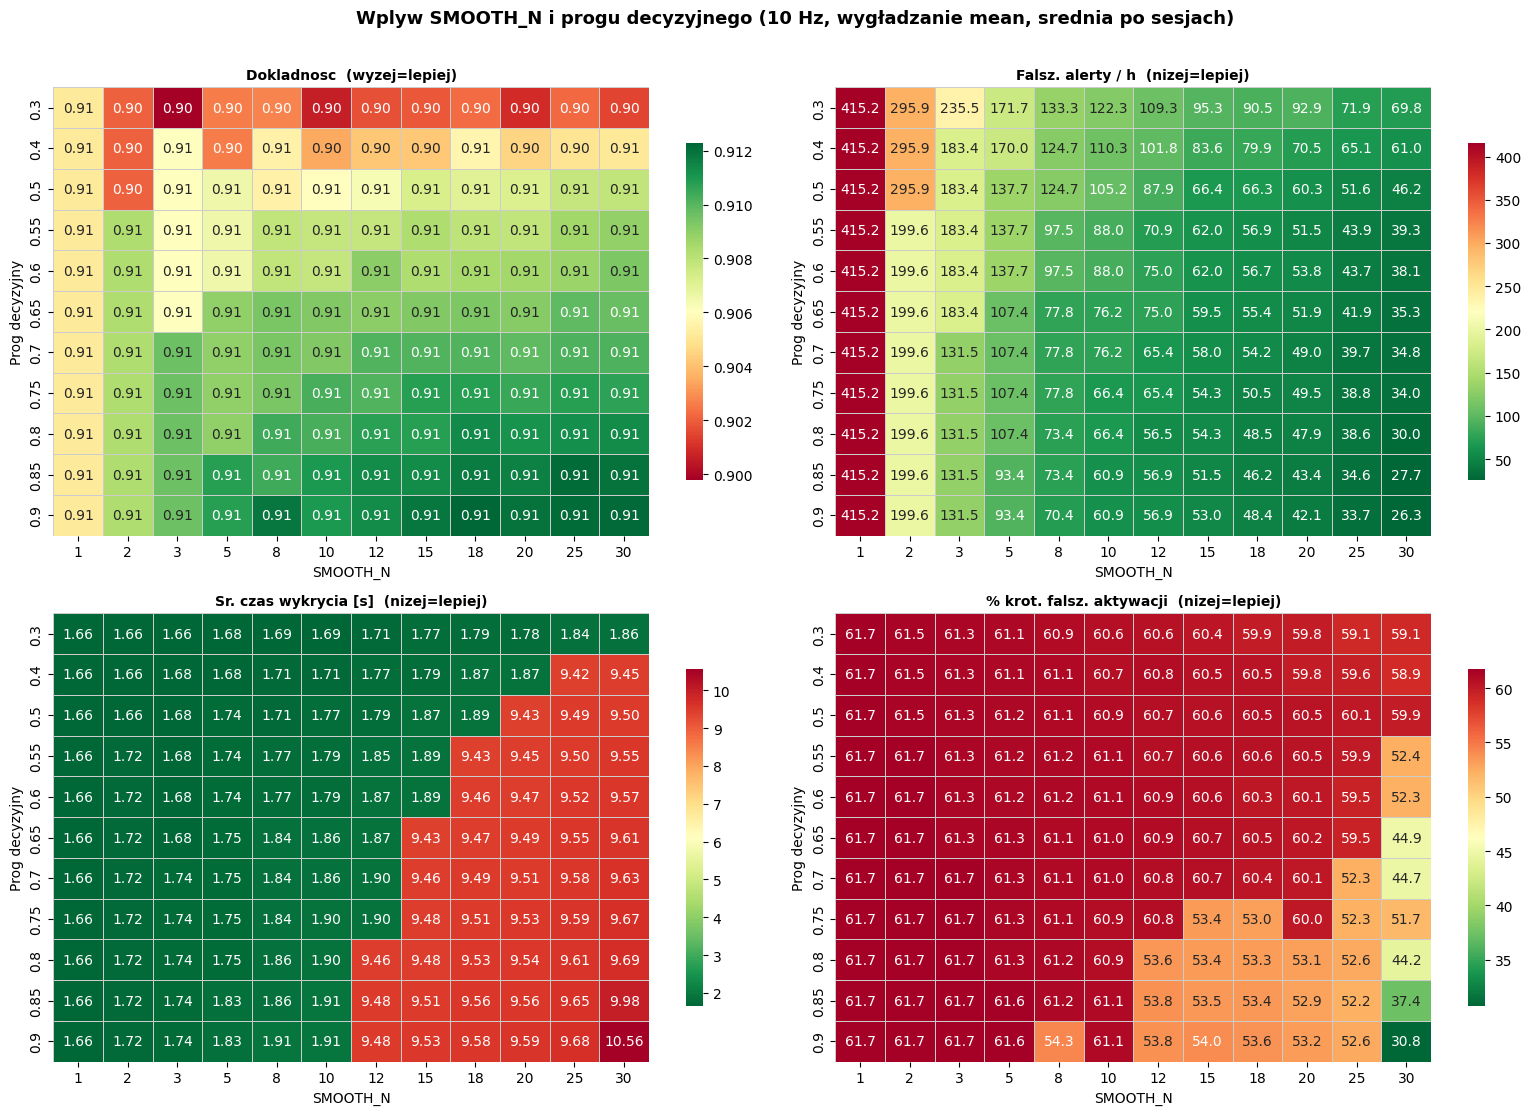

Zapisano: C:\Users\emilk\PycharmProjects\posture_analysis\data\reports\grid_heatmap_smooth.png


In [9]:
agg_10_mean = agg[(agg["fps_step"] == 1) & (agg["smoothing_type"] == "mean")].copy()

metrics_cfg = [
    ("accuracy",        "Accuracy",               False, ".2f"),
    ("false_alerts_h",  "False alerts / h",         True,  ".1f"),
    ("avg_detection_s", "Avg. detection time [s]",     True,  ".2f"),
    ("pct_short_false", "% short false activations",  True,  ".1f"),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

for ax, (metric, title, lower_better, fmt_ann) in zip(axes.flat, metrics_cfg):
    pivot = agg_10_mean.pivot_table(
        values=metric, index="threshold", columns="smooth_n", aggfunc="mean"
    )
    sns.heatmap(
        pivot, ax=ax,
        annot=True, fmt=fmt_ann,
        cmap="RdYlGn_r" if lower_better else "RdYlGn",
        linewidths=0.4, linecolor="#ccc",
        cbar_kws={"shrink": 0.75},
    )
    suffix = "(lower=better)" if lower_better else "(higher=better)"
    ax.set_title(f"{title}  {suffix}", fontsize=10, fontweight="bold")
    ax.set_xlabel("SMOOTH_N")
    ax.set_ylabel("Decision threshold")

plt.suptitle(
    "Effect of SMOOTH_N and the decision threshold (10 Hz, mean smoothing, averaged across sessions)",
    fontsize=13, fontweight="bold", y=1.01
)
plt.tight_layout()
hm_path = os.path.join(REPORTS_DIR, "grid_heatmap_smooth.png")
plt.savefig(hm_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {hm_path}")

## 7. Effect of sampling frequency (all values)

Parametry stale: SMOOTH_N=20, prog=0.7, typ=mean
  WPLYW CZESTOTLIWOSCI PROBKOWANIA
fps_label        accuracy false_alerts_h avg_detection_s pct_short_false
  30.0 Hz 0.9099 (90.99%)        49.03/h         9.507 s           60.1%
  15.0 Hz 0.9101 (91.01%)        26.50/h        10.556 s           22.6%
  10.0 Hz 0.9115 (91.15%)        19.92/h        10.939 s           20.4%
   5.0 Hz 0.9137 (91.37%)        11.96/h        11.456 s            7.1%
   3.0 Hz 0.9104 (91.04%)         6.97/h        19.994 s            4.9%
   2.0 Hz 0.9095 (90.95%)         1.91/h        25.630 s            0.9%


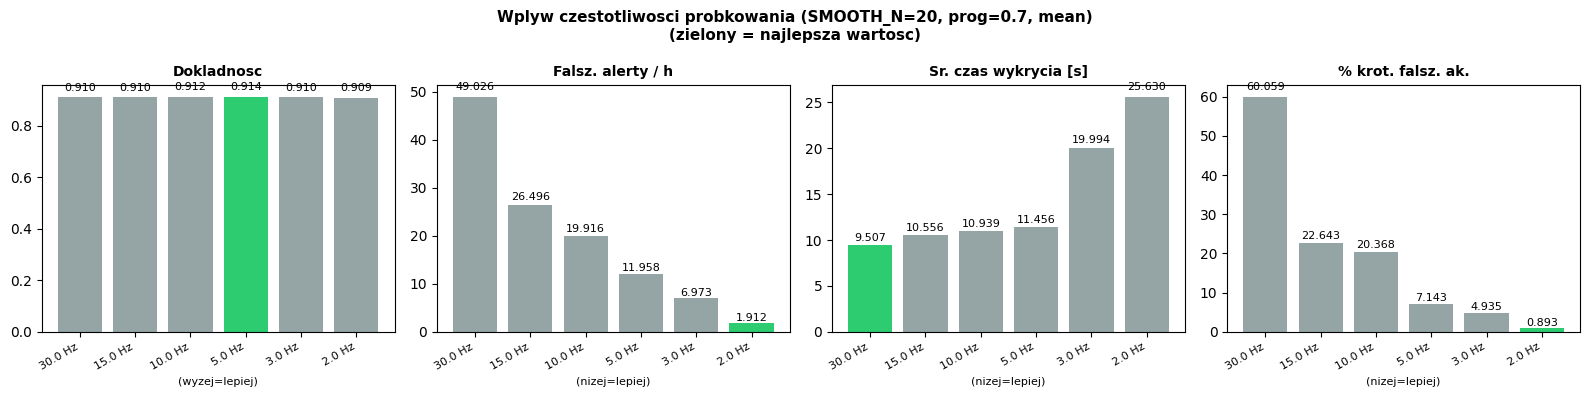

Zapisano: C:\Users\emilk\PycharmProjects\posture_analysis\data\reports\grid_fps_comparison.png


In [10]:
# Compare FPS with the system's current parameters held FIXED
# (SMOOTH_N=20, threshold=0.70, mean) -- isolates the effect of the sampling frequency only.
# If we picked the optimal N and threshold for each FPS, the FPS effect would
# be inseparable from the effect of the other parameters.
FIXED_SMOOTH_N   = 20
FIXED_THRESHOLD  = 0.70
FIXED_STYPE      = "mean"

fps_agg = (
    agg[
        (agg["smooth_n"]       == FIXED_SMOOTH_N)
      & (agg["threshold"]      == FIXED_THRESHOLD)
      & (agg["smoothing_type"] == FIXED_STYPE)
    ]
    .groupby(["fps_step", "effective_fps"])[["accuracy","false_alerts_h","avg_detection_s","pct_short_false"]]
    .mean()
    .reset_index()
    .sort_values("effective_fps", ascending=False)
)

print(f"Fixed parameters: SMOOTH_N={FIXED_SMOOTH_N}, threshold={FIXED_THRESHOLD}, type={FIXED_STYPE}")
print("=" * 60)
print("  EFFECT OF SAMPLING FREQUENCY")
print("=" * 60)
disp = fps_agg[["effective_fps","accuracy","false_alerts_h","avg_detection_s","pct_short_false"]].copy()
disp["fps_label"]       = disp["effective_fps"].apply(lambda x: f"{x:.1f} Hz")
disp["accuracy"]        = disp["accuracy"].map(lambda x: f"{x:.4f} ({x:.2%})")
disp["false_alerts_h"]  = disp["false_alerts_h"].map("{:.2f}/h".format)
disp["avg_detection_s"] = disp["avg_detection_s"].map("{:.3f} s".format)
disp["pct_short_false"] = disp["pct_short_false"].map("{:.1f}%".format)
print(disp[["fps_label","accuracy","false_alerts_h","avg_detection_s","pct_short_false"]].to_string(index=False))

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
metrics_fps = [
    ("accuracy",        "Accuracy",           False),
    ("false_alerts_h",  "False alerts / h",    True),
    ("avg_detection_s", "Avg. detection time [s]", True),
    ("pct_short_false", "% short false act.",    True),
]
labels = [f"{v:.1f} Hz" for v in fps_agg["effective_fps"].values]
for ax, (col, title, low_better) in zip(axes, metrics_fps):
    vals = fps_agg[col].values
    colors = ["#2ecc71" if (not low_better and v == vals.max()) or
              (low_better and v == vals.min()) else "#95a5a6" for v in vals]
    bars = ax.bar(labels, vals, color=colors)
    ax.set_title(title, fontsize=10, fontweight="bold")
    ax.set_xticklabels(labels, rotation=30, ha="right", fontsize=8)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.02,
                f"{v:.3f}", ha="center", va="bottom", fontsize=8)
    ax.set_xlabel("(lower=better)" if low_better else "(higher=better)", fontsize=8)
plt.suptitle(
    f"Effect of sampling frequency (SMOOTH_N={FIXED_SMOOTH_N}, threshold={FIXED_THRESHOLD}, {FIXED_STYPE})\n(green = best value)",
    fontsize=11, fontweight="bold"
)
plt.tight_layout()
fps_path = os.path.join(REPORTS_DIR, "grid_fps_comparison.png")
plt.savefig(fps_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {fps_path}")

## 8. Comparison of smoothing types (mean vs majority-vote vs median)

  POROWNANIE TYPOW WYGŁADZANIA (przy swoich optymalnych parametrach)
Typ wygładzania  Optymalny SMOOTH_N  Optymalny prog  Optymalny FPS Dokladnosc FA/h Wykrycie [s] % Kr.FA  Score
           mean                   8            0.65            2.0     0.9147 8.70       11.417     5.7 0.9271
       majority                   8            0.65            2.0     0.9147 8.70       11.417     5.7 0.9271
         median                  18            0.50            3.0     0.9129 9.01       11.358     1.1 0.9126


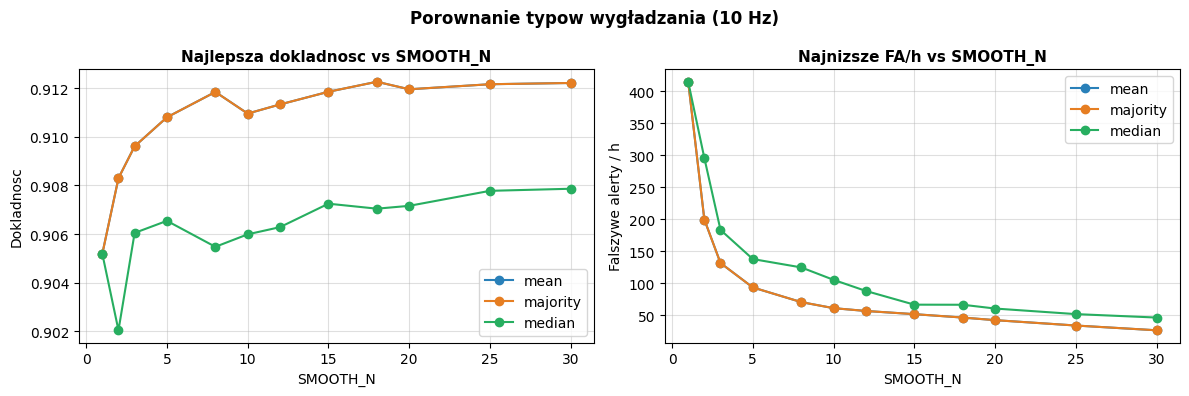

Zapisano: C:\Users\emilk\PycharmProjects\posture_analysis\data\reports\grid_smoothing_types.png


In [11]:
# Best N and fps for each type – compare the types at their own optimal thresholds
type_summary = []
for stype in SMOOTHING_TYPES:
    sub = agg[agg["smoothing_type"] == stype]
    if len(sub) == 0:
        continue
    best_row = sub.loc[sub["score"].idxmax()]
    type_summary.append({
        "Smoothing type":     stype,
        "Optimal SMOOTH_N":   int(best_row["smooth_n"]),
        "Optimal threshold":  best_row["threshold"],
        "Optimal FPS":        best_row["effective_fps"],
        "Accuracy":         best_row["accuracy"],
        "FA/h":               best_row["false_alerts_h"],
        "Detection [s]":       best_row["avg_detection_s"],
        "% Short FA":            best_row["pct_short_false"],
        "Score":              best_row["score"],
    })

type_df = pd.DataFrame(type_summary)
print("=" * 75)
print("  SMOOTHING TYPE COMPARISON (each at its own optimal parameters)")
print("=" * 75)
fmt2 = {
    "Accuracy": "{:.4f}", "FA/h": "{:.2f}",
    "Detection [s]": "{:.3f}", "% Short FA": "{:.1f}", "Score": "{:.4f}"
}
type_disp = type_df.copy()
for col, f in fmt2.items():
    type_disp[col] = type_disp[col].apply(lambda v: f.format(v) if not pd.isna(v) else "N/D")
print(type_disp.to_string(index=False))

# Line charts: how does each smoothing type react to changes in SMOOTH_N?
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for stype, color in zip(SMOOTHING_TYPES, ["#2980b9","#e67e22","#27ae60"]):
    sub = agg[(agg["smoothing_type"] == stype) & (agg["fps_step"] == 1)]
    if stype == "median":
        by_n = sub.groupby("smooth_n")["accuracy"].mean().reset_index()
        by_n_fa = sub.groupby("smooth_n")["false_alerts_h"].mean().reset_index()
    else:
        by_n = sub.groupby("smooth_n")["accuracy"].max().reset_index()
        by_n_fa = sub.groupby("smooth_n")["false_alerts_h"].min().reset_index()
    axes[0].plot(by_n["smooth_n"], by_n["accuracy"], marker="o", label=stype, color=color)
    axes[1].plot(by_n_fa["smooth_n"], by_n_fa["false_alerts_h"], marker="o", label=stype, color=color)

for ax, (title, ylabel) in zip(axes, [
    ("Best accuracy vs SMOOTH_N", "Accuracy"),
    ("Lowest FA/h vs SMOOTH_N", "False alerts / h")
]):
    ax.set_xlabel("SMOOTH_N")
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.legend()
    ax.grid(alpha=0.4)
plt.suptitle("Smoothing type comparison (10 Hz)", fontsize=12, fontweight="bold")
plt.tight_layout()
st_path = os.path.join(REPORTS_DIR, "grid_smoothing_types.png")
plt.savefig(st_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {st_path}")

## 9. Keypoint subset analysis

We train a separate RF model (5-fold cross-validation) for each feature subset.
This answers the question: are the nose, eyes and ears really needed?

| Subset | Points | Features |
|---------|--------|-------|
| All (baseline) | nose, eyes, ears, shoulders | 21 |
| No nose (6 pts) | eyes, ears, shoulders | 18 |
| Shoulders + ears + nose (5 pts) | nose, ears, shoulders | 15 |
| Shoulders + ears (4 pts) | ears, shoulders | 12 |
| Shoulders + nose (3 pts) | nose, shoulders | 9 |
| Shoulders only (2 pts) | shoulders | 6 |

In [12]:
DATA_CSV = os.path.join(DATA_DIR, "posture_data.csv")

if not os.path.exists(DATA_CSV):
    print(f"ERROR: {DATA_CSV} not found")
    print("Section 9 requires the posture_data.csv file with the training data.")
else:
    raw = pd.read_csv(DATA_CSV)
    print(f"Loaded posture_data.csv: {raw.shape[0]} samples, {raw.shape[1]} columns")
    print(f"Class distribution: {raw['label'].value_counts().to_dict()}")
    print(f"Columns: {list(raw.columns)}")

Zaladowano posture_data.csv: 3058 probek, 22 kolumn
Rozklad klas: {0: 1553, 1: 1505}
Kolumny: ['nose_x', 'nose_y', 'nose_z', 'left_eye_x', 'left_eye_y', 'left_eye_z', 'right_eye_x', 'right_eye_y', 'right_eye_z', 'left_ear_x', 'left_ear_y', 'left_ear_z', 'right_ear_x', 'right_ear_y', 'right_ear_z', 'left_shoulder_x', 'left_shoulder_y', 'left_shoulder_z', 'right_shoulder_x', 'right_shoulder_y', 'right_shoulder_z', 'label']


In [13]:
LANDMARKS_ALL = ["nose","left_eye","right_eye","left_ear","right_ear",
                  "left_shoulder","right_shoulder"]

KEYPOINT_SUBSETS = {
    "All (7 pts)":                 LANDMARKS_ALL,
    "No nose (6 pts)":             [l for l in LANDMARKS_ALL if l != "nose"],
    "Shoulders + ears + nose (5 pts)":["nose","left_ear","right_ear","left_shoulder","right_shoulder"],
    "Shoulders + ears (4 pts)":    ["left_ear","right_ear","left_shoulder","right_shoulder"],
    "Shoulders + nose (3 pts)":    ["nose","left_shoulder","right_shoulder"],
    "Shoulders only (2 pts)":      ["left_shoulder","right_shoulder"],
}

def get_feature_cols(subset_landmarks, all_cols):
    axes = ["_x", "_y", "_z"]
    return [
        col for col in all_cols if col != "label"
        and any(col.startswith(lm + ax) or col == lm + ax
                for lm in subset_landmarks for ax in axes)
    ]

if os.path.exists(DATA_CSV):
    all_cols = list(raw.columns)
    print(f"Defined {len(KEYPOINT_SUBSETS)} unique subsets:")
    for name, lms in KEYPOINT_SUBSETS.items():
        cols = get_feature_cols(lms, all_cols)
        print(f"  {name:<35} {len(lms)} pts  {len(cols)} features")

Zdefiniowano 6 unikalnych podzbiorow:
  Wszystkie (7 pkt)                   7 pkt  21 cech
  Bez nosa (6 pkt)                    6 pkt  18 cech
  Ramiona + uszy + nos (5 pkt)        5 pkt  15 cech
  Ramiona + uszy (4 pkt)              4 pkt  12 cech
  Ramiona + nos (3 pkt)               3 pkt  9 cech
  Tylko ramiona (2 pkt)               2 pkt  6 cech


In [14]:
kp_results = []

if os.path.exists(DATA_CSV):
    X_all = raw.drop(columns=["label"]).values
    y     = raw["label"].values
    all_cols = list(raw.columns)

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    for subset_name, landmarks in KEYPOINT_SUBSETS.items():
        feat_cols = get_feature_cols(landmarks, all_cols)
        if len(feat_cols) == 0:
            print(f"WARNING: no columns for {subset_name} – skipping")
            continue
        feat_idx = [all_cols.index(c) for c in feat_cols if c in all_cols]
        X_sub = X_all[:, feat_idx]

        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X_sub)

        # Cross-val on the same RF as production (n_estimators=100, max_depth=10)
        rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
        scores_acc = cross_val_score(rf, X_scaled, y, cv=cv, scoring="accuracy")
        scores_f1  = cross_val_score(rf, X_scaled, y, cv=cv, scoring="f1")

        kp_results.append({
            "Subset": subset_name,
            "Points": len(landmarks),
            "Features":  len(feat_cols),
            "Acc_mean":   scores_acc.mean(),
            "Acc_std":    scores_acc.std(),
            "F1_mean":    scores_f1.mean(),
            "F1_std":     scores_f1.std(),
        })
        print(f"  [{subset_name}] acc={scores_acc.mean():.4f} ± {scores_acc.std():.4f}  "
              f"F1={scores_f1.mean():.4f} ± {scores_f1.std():.4f}")

    kp_df = pd.DataFrame(kp_results)
    kp_csv = os.path.join(REPORTS_DIR, "grid_keypoints.csv")
    kp_df.to_csv(kp_csv, index=False)
    print(f"\nSaved: {kp_csv}")
else:
    print("Section skipped – posture_data.csv not found")

  [Wszystkie (7 pkt)] acc=0.9863 ± 0.0049  F1=0.9859 ± 0.0051
  [Bez nosa (6 pkt)] acc=0.9859 ± 0.0039  F1=0.9856 ± 0.0041
  [Ramiona + uszy + nos (5 pkt)] acc=0.9859 ± 0.0047  F1=0.9856 ± 0.0049
  [Ramiona + uszy (4 pkt)] acc=0.9856 ± 0.0044  F1=0.9852 ± 0.0047
  [Ramiona + nos (3 pkt)] acc=0.9876 ± 0.0064  F1=0.9872 ± 0.0067
  [Tylko ramiona (2 pkt)] acc=0.9794 ± 0.0083  F1=0.9788 ± 0.0087

Zapisano: C:\Users\emilk\PycharmProjects\posture_analysis\data\reports\grid_keypoints.csv


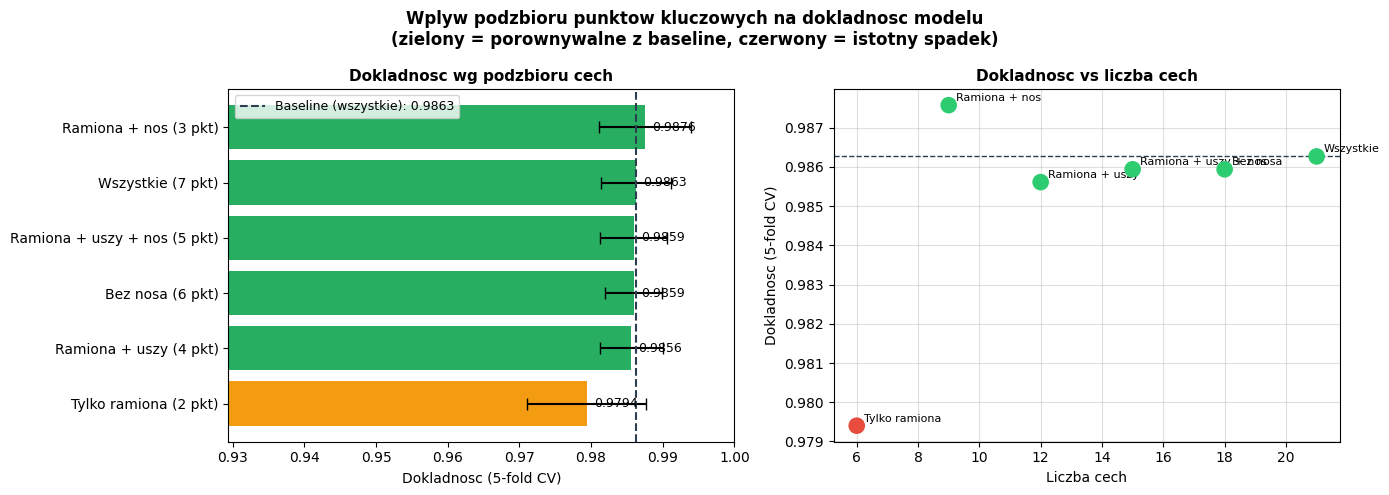

Zapisano: C:\Users\emilk\PycharmProjects\posture_analysis\data\reports\grid_keypoints_plot.png

  TABELA: PODZBIORY PUNKTOW KLUCZOWYCH (posortowane wg dokladnosci)
                     Podzial  Punkty  Cechy Acc_mean Acc_std F1_mean Acc_drop %
       Ramiona + nos (3 pkt)       3      9   0.9876  0.0064  0.9872     -0.13%
           Wszystkie (7 pkt)       7     21   0.9863  0.0049  0.9859     +0.00%
Ramiona + uszy + nos (5 pkt)       5     15   0.9859  0.0047  0.9856     +0.03%
            Bez nosa (6 pkt)       6     18   0.9859  0.0039  0.9856     +0.03%
      Ramiona + uszy (4 pkt)       4     12   0.9856  0.0044  0.9852     +0.07%
       Tylko ramiona (2 pkt)       2      6   0.9794  0.0083  0.9788     +0.69%


In [15]:
if kp_results:
    kp_df_sorted = kp_df.sort_values("Acc_mean", ascending=True)
    baseline_acc = kp_df[kp_df["Subset"].str.contains("All")]["Acc_mean"].values[0]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Accuracy with error bars
    colors = [
        "#27ae60" if abs(row["Acc_mean"] - baseline_acc) < 0.005  # comparable to baseline
        else ("#e74c3c" if row["Acc_mean"] < baseline_acc - 0.01 else "#f39c12")
        for _, row in kp_df_sorted.iterrows()
    ]
    bars = axes[0].barh(kp_df_sorted["Subset"], kp_df_sorted["Acc_mean"],
                        xerr=kp_df_sorted["Acc_std"], color=colors,
                        capsize=4, error_kw={"elinewidth": 1.5})
    axes[0].axvline(x=baseline_acc, color="#2c3e50", linestyle="--", linewidth=1.5,
                    label=f"Baseline (all): {baseline_acc:.4f}")
    axes[0].set_xlabel("Accuracy (5-fold CV)", fontsize=10)
    axes[0].set_title("Accuracy by feature subset", fontsize=11, fontweight="bold")
    axes[0].legend(fontsize=9)
    axes[0].set_xlim(max(0, kp_df_sorted["Acc_mean"].min() - 0.05), 1.0)
    for bar, (_, row) in zip(bars, kp_df_sorted.iterrows()):
        axes[0].text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
                     f"{row['Acc_mean']:.4f}", va="center", fontsize=9)

    # Accuracy drop vs number of features
    kp_df_plot = kp_df.copy()
    kp_df_plot["Acc_drop"] = baseline_acc - kp_df_plot["Acc_mean"]
    axes[1].scatter(kp_df_plot["Features"], kp_df_plot["Acc_mean"],
                    s=120, c=["#2ecc71" if d < 0.005 else "#e74c3c" for d in kp_df_plot["Acc_drop"]],
                    zorder=5)
    for _, row in kp_df_plot.iterrows():
        axes[1].annotate(
            row["Subset"].split("(")[0].strip(),
            (row["Features"], row["Acc_mean"]),
            textcoords="offset points", xytext=(5, 3), fontsize=8
        )
    axes[1].set_xlabel("Number of features", fontsize=10)
    axes[1].set_ylabel("Accuracy (5-fold CV)", fontsize=10)
    axes[1].set_title("Accuracy vs number of features", fontsize=11, fontweight="bold")
    axes[1].grid(alpha=0.4)
    axes[1].axhline(y=baseline_acc, color="#2c3e50", linestyle="--", linewidth=1)

    plt.suptitle(
        "Effect of the keypoint subset on model accuracy\n"
        "(green = comparable to baseline, red = significant drop)",
        fontsize=12, fontweight="bold"
    )
    plt.tight_layout()
    kp_path = os.path.join(REPORTS_DIR, "grid_keypoints_plot.png")
    plt.savefig(kp_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {kp_path}")

    # Comparison table
    print("\n" + "=" * 72)
    print("  TABLE: KEYPOINT SUBSETS (sorted by accuracy)")
    print("=" * 72)
    tab = kp_df.sort_values("Acc_mean", ascending=False).copy()
    tab["Acc_drop %"] = ((baseline_acc - tab["Acc_mean"]) * 100).map("{:+.2f}%".format)
    tab["Acc_mean"]   = tab["Acc_mean"].map("{:.4f}".format)
    tab["Acc_std"]    = tab["Acc_std"].map("{:.4f}".format)
    tab["F1_mean"]    = tab["F1_mean"].map("{:.4f}".format)
    print(tab[["Subset","Points","Features","Acc_mean","Acc_std","F1_mean","Acc_drop %"]].to_string(index=False))
    print("=" * 72)

In [16]:
# Feature importance from the production model (supplement – does not require posture_data.csv)
model_path = os.path.join(MODELS_DIR, "posture_model.pkl")
if os.path.exists(model_path):
    model = joblib.load(model_path)
    AXES_3 = ["_x", "_y", "_z"]
    feature_names = [f"{lm}{ax}" for lm in LANDMARKS_ALL for ax in AXES_3]
    imp_df = pd.DataFrame({"feature": feature_names, "importance": model.feature_importances_})
    imp_df["keypoint"] = imp_df["feature"].apply(lambda x: x[:-2])   # strip _x/_y/_z
    kp_imp = imp_df.groupby("keypoint")["importance"].sum()
    kp_imp = kp_imp.reindex(LANDMARKS_ALL)
    total_imp = kp_imp.sum()

    print("=" * 55)
    print("  KEYPOINT IMPORTANCE (from the production RF model)")
    print("=" * 55)
    for kp, v in kp_imp.sort_values(ascending=False).items():
        bar = "#" * int(v / total_imp * 40)
        print(f"  {kp:<22} {v:.4f}  ({v/total_imp*100:5.1f}%)  {bar}")
    print("=" * 55)

else:
    print(f"Model not found: {model_path}")

  WAZNOSC PUNKTOW KLUCZOWYCH (wg prod. modelu RF)
  left_shoulder          0.1713  ( 17.1%)  ######
  left_ear               0.1544  ( 15.4%)  ######
  left_eye               0.1459  ( 14.6%)  #####
  nose                   0.1428  ( 14.3%)  #####
  right_shoulder         0.1340  ( 13.4%)  #####
  right_ear              0.1300  ( 13.0%)  #####
  right_eye              0.1216  ( 12.2%)  ####


## 10. Summary and recommendations

In [17]:
CURRENT = {"smooth_n": 20, "threshold": 0.70, "fps_step": 3, "smoothing_type": "mean"}

best_row = agg.loc[agg["score"].idxmax()]
current_mask = (
    (agg["smooth_n"]       == CURRENT["smooth_n"])
  & (agg["threshold"]      == CURRENT["threshold"])
  & (agg["fps_step"]       == CURRENT["fps_step"])
  & (agg["smoothing_type"] == CURRENT["smoothing_type"])
)
current_row = agg[current_mask].iloc[0] if current_mask.any() else None

print("=" * 75)
print("  RECOMMENDATIONS SUMMARY")
print("=" * 75)

rec_rows = [
    ("SMOOTH_N",     CURRENT["smooth_n"],    int(best_row["smooth_n"]),
                     "Prediction smoothing window"),
    ("Threshold",    f"{CURRENT['threshold']:.0%}",
                     f"{best_row['threshold']:.0%}",
                     "Min. share of bad frames in the window"),
    ("Smooth type",  CURRENT["smoothing_type"],
                     best_row["smoothing_type"],
                     "Smoothing method"),
    ("Sampling",     "10 Hz",
                     f"{best_row['effective_fps']:.1f} Hz",
                     "Processing frequency"),
]
rec_df = pd.DataFrame(rec_rows, columns=["Parameter","Current","Optimal","Description"])
rec_df["Change"] = rec_df.apply(
    lambda r: "no change" if str(r["Current"]) == str(r["Optimal"]) else "YES", axis=1
)
print(rec_df.to_string(index=False))

print()
print("  METRICS: current vs optimal (averaged across sessions)")
print("-" * 75)
if current_row is not None:
    metrics_labels = ["Accuracy","FA/h","Detection [s]","% Short FA","Score"]
    metrics_cols   = ["accuracy","false_alerts_h","avg_detection_s","pct_short_false","score"]
    metrics_fmts   = ["{:.4f}","{:.2f}","{:.3f}","{:.1f}","{:.4f}"]
    comp_df = pd.DataFrame({
        "Metric":     metrics_labels,
        "Current":   [metrics_fmts[i].format(current_row[metrics_cols[i]])
                      for i in range(len(metrics_cols))],
        "Optimal":   [metrics_fmts[i].format(best_row[metrics_cols[i]])
                      for i in range(len(metrics_cols))],
    })
    print(comp_df.to_string(index=False))
else:
    print("(Current configuration not found in the grid search results)")

print("=" * 75)

# Save the recommendations
rec_df.to_csv(os.path.join(REPORTS_DIR, "grid_search_rekomendacje.csv"), index=False)
print("\nSaved recommendations: data/reports/grid_search_rekomendacje.csv")

  PODSUMOWANIE REKOMENDACJI
   Parametr Biezaca Optymalna                           Opis Zmiana
   SMOOTH_N      20         8     Okno wygładzania predykcji    TAK
       Prog     70%       65% Min. udzial klatek=bad w oknie    TAK
  Typ wygl.    mean  majority             Metoda wygładzania    TAK
Probkowanie   10 Hz    2.0 Hz    Czestotliwosc przetwarzania    TAK

  METRYKI: biezace vs optymalne (srednia po sesjach)
---------------------------------------------------------------------------
     Metryka Biezace Optymalne
  Dokladnosc  0.9115    0.9147
        FA/h   19.92      8.70
Wykrycie [s]  10.939    11.417
     % Kr.FA    20.4       5.7
       Score  0.8406    0.9271

Zapisano rekomendacje: data/reports/grid_search_rekomendacje.csv


## 11. Optimal smoothing parameters for selected sampling frequencies

The previous section picked a single globally best configuration. Here we answer a different question:
**assuming the system runs at a specific FPS (10 / 5 / 3 Hz), which combination of SMOOTH_N and θ gives the best result?**

Approach: from the `agg` table (scores computed globally) we filter the rows for the given FPS
and pick the row with the highest composite score. This keeps the scoring consistent
with the ranking from section 5, and the table is fully reproducible from the `grid_search_wyniki.csv` file.

In [18]:
# Optimal SMOOTH_N and threshold for each FPS tested (smoothing type: mean)
# Scoring identical to section 5 – we reuse the already computed `agg` table.

TARGET_FPS   = [10.0, 5.0, 3.0]
STYPE_FIXED  = "mean"

per_fps_rows = []
for fps in TARGET_FPS:
    sub = agg[(agg["effective_fps"] == fps) & (agg["smoothing_type"] == STYPE_FIXED)]
    if sub.empty:
        print(f"NO data for {fps} Hz – check FPS_STEPS in the configuration")
        continue
    best = sub.loc[sub["score"].idxmax()]
    per_fps_rows.append({
        "FPS [Hz]":   fps,
        "SMOOTH_N":   int(best["smooth_n"]),
        "Threshold":       best["threshold"],
        "Accuracy":   best["accuracy"],
        "FA/h":       best["false_alerts_h"],
        "Detection_s": best["avg_detection_s"],
        "Short_%":  best["pct_short_false"],
        "Score":      best["score"],
    })

per_fps_df = pd.DataFrame(per_fps_rows)

# Save to CSV (source for the tab:best_params table in the report)
per_fps_csv = os.path.join(REPORTS_DIR, "grid_best_per_fps.csv")
per_fps_df.to_csv(per_fps_csv, index=False)

# Print a readable table
print("=" * 75)
print("  OPTIMAL SMOOTH_N AND THRESHOLD FOR EACH FPS (type: mean, composite score)")
print("  Scoring: acc 40% | FA/h 30% | detection time 15% | short FA 15%")
print("=" * 75)
disp = per_fps_df.copy()
disp["Accuracy"]   = disp["Accuracy"].map("{:.3f}".format)
disp["FA/h"]       = disp["FA/h"].map("{:.1f}".format)
disp["Detection_s"] = disp["Detection_s"].map("{:.1f} s".format)
disp["Short_%"]  = disp["Short_%"].map("{:.1f}%".format)
disp["Score"]      = disp["Score"].map("{:.3f}".format)
print(disp.to_string(index=False))
print("=" * 75)
print(f"\nSaved: {per_fps_csv}")

  OPTYMALNE SMOOTH_N I PRÓG DLA KAŻDEGO FPS (typ: mean, composite score)
  Scoring: acc 40% | FA/h 30% | czas wykrycia 15% | krótkie FA 15%
 FPS [Hz]  SMOOTH_N  Prog Accuracy FA/h Wykrycie_s Krotkie_% Score
     10.0        30   0.6    0.913 15.6     11.0 s     18.9% 0.866
      5.0        20   0.7    0.914 12.0     11.5 s      7.1% 0.907
      3.0        12   0.7    0.914  8.7     11.5 s      5.7% 0.917

Zapisano: C:\Users\emilk\PycharmProjects\posture_analysis\data\reports\grid_best_per_fps.csv


## 12. Practical recommendation vs global optimum

Section 10 points to the globally optimal configuration: **2 Hz / N=8 / majority / θ=65%** (FA/h=8.7).
However, at 2 Hz the average bad-posture detection time is **25.6 s** (see section 7),
which is impractical from an office-ergonomics point of view.

Using the criterion **detection time < 12 s**, the recommended configuration is **5 Hz**
with the current smoothing parameters (N=20, θ=0.70, mean).
This is the only change required in `server.py` — switching the sampling frequency.

The `grid_rekomendacja_praktyczna.csv` file contains this configuration as a separate artifact,
consistent with the `tab:gridsearch_summary` table in the report.

In [19]:
# Practical recommendation: 5 Hz with the current smoothing parameters.
# The global optimum (section 10) is 2 Hz / N=8 / majority / theta=65%,
# but a 25.6 s detection time is impractical. Criterion: det < 12 s.

PRACTICAL = {"smooth_n": 20, "threshold": 0.70, "fps_step": 6, "smoothing_type": "mean"}
# fps_step=6 → effective_fps = 30/6 = 5 Hz

practical_mask = (
    (agg["smooth_n"]       == PRACTICAL["smooth_n"])
  & (agg["threshold"]      == PRACTICAL["threshold"])
  & (agg["fps_step"]       == PRACTICAL["fps_step"])
  & (agg["smoothing_type"] == PRACTICAL["smoothing_type"])
)
practical_row = agg[practical_mask].iloc[0]

global_row = agg.loc[agg["score"].idxmax()]

practical_df = pd.DataFrame([
    {
        "Type":          "Global optimum (mathematical)",
        "SMOOTH_N":     int(global_row["smooth_n"]),
        "Threshold":         global_row["threshold"],
        "FPS":          global_row["effective_fps"],
        "Smoothing":    global_row["smoothing_type"],
        "FA/h":         round(global_row["false_alerts_h"], 2),
        "Detection_s":   round(global_row["avg_detection_s"], 2),
        "Accuracy":     round(global_row["accuracy"], 4),
        "Note":         "Detection time 25.6 s – impractical",
    },
    {
        "Type":          "Practical recommendation (det < 12 s)",
        "SMOOTH_N":     int(practical_row["smooth_n"]),
        "Threshold":         practical_row["threshold"],
        "FPS":          practical_row["effective_fps"],
        "Smoothing":    practical_row["smoothing_type"],
        "FA/h":         round(practical_row["false_alerts_h"], 2),
        "Detection_s":   round(practical_row["avg_detection_s"], 2),
        "Accuracy":     round(practical_row["accuracy"], 4),
        "Note":         "Only change: FPS 10 Hz -> 5 Hz in server.py",
    },
])

practical_csv = os.path.join(REPORTS_DIR, "grid_rekomendacja_praktyczna.csv")
practical_df.to_csv(practical_csv, index=False)

print("=" * 70)
print("  GLOBAL OPTIMUM vs PRACTICAL RECOMMENDATION")
print("=" * 70)
print(practical_df[["Type","SMOOTH_N","Threshold","FPS","Smoothing","FA/h","Detection_s","Accuracy"]].to_string(index=False))
print("=" * 70)
print(f"\nSaved: {practical_csv}")

  GLOBALNY OPTIMUM vs REKOMENDACJA PRAKTYCZNA
                                 Typ  SMOOTH_N  Prog  FPS Smoothing  FA/h  Wykrycie_s  Accuracy
     Globalny optimum (matematyczny)         8  0.65  2.0  majority  8.70       11.42    0.9147
Rekomendacja praktyczna (det < 12 s)        20  0.70  5.0      mean 11.96       11.46    0.9137

Zapisano: C:\Users\emilk\PycharmProjects\posture_analysis\data\reports\grid_rekomendacja_praktyczna.csv
